# Microbial Diversity Dynamics & Nutritional Characterisation of Fermented Sour Rice
### Standalone Reproducible Workflow for Spearman Rank Correlation & Multivariate Redundancy Analysis (RDA)

This interactive notebook reproduces the statistical and numerical ecology findings presented in:
> **"Microbial Diversity Dynamics and Nutritional Characterisation of Selected Fermented Sour Rice Varieties: A 16S rRNA Amplicon Sequencing Study"**  
> *Cultivars:* ADT36, CO43, Mappillai Samba (MS), Improved White Ponni (IWP), White Ponni Unpolished (WPU), and CR1009 (Ration Rice) at 16 h established fermentation.

---

### Objectives:
1. Couple 16S rRNA taxonomic abundance (Genus level) with 13 nutritional, mineral, and antioxidant parameters.
2. Calculate non-parametric Spearman rank correlation ($r$) with Benjamini-Hochberg False Discovery Rate (FDR $q$-values).
3. Validate linear response gradient via Detrended Correspondence Analysis (DCA Axis 1 = 2.665 SD < 3.0 SD).
4. Perform Constrained Redundancy Analysis (RDA) biplot ordination capturing 75.58% constrained variance.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

# Path definitions relative to repository root
DATA_DIR = os.path.join("..", "data")
RESULTS_DIR = os.path.join("..", "results")

print("Packages imported successfully. Ready for analysis.")


Packages imported successfully. Ready for analysis.


## 1. Load and Harmonize 16S Taxonomic Abundances & Nutritional Assays
We parse the top 12 predominant bacterial genera from 16S rRNA amplicon sequencing data and map them against triplicate nutritional means for the six cultivars at 16 h.

In [2]:
tax_path = os.path.join(DATA_DIR, "taxasums.xlsx")
nut_path = os.path.join(DATA_DIR, "physicochemical_data.xlsx")

df_tax = pd.read_excel(tax_path)
samples_16 = ['ADT36-16', 'CO43-16', 'Mappillai-Samba-16', 'Ponni-Polished-16', 'Ponni-Unpolished-16', 'Ration-Rice-16']
cultivar_names = ['ADT36', 'CO43', 'MS', 'IWP', 'WPU', 'CR1009']

df_tax['Genus'] = df_tax['Taxonomy'].apply(lambda x: x.split(';')[-1].strip() if len(x.split(';')) >= 6 else 'Unclassified')

for s in samples_16:
    df_tax[s + '_pct'] = (df_tax[s] / df_tax[s].sum()) * 100.0

g_df = df_tax.groupby('Genus')[[s + '_pct' for s in samples_16]].sum()
g_df.columns = cultivar_names

major_genera = [
    'Bacillus', 'Acinetobacter', 'Ralstonia', 'Stenotrophomonas', 'Idiomarina',
    'Bacteroides', 'Lactococcus', 'Weissella', 'Lactobacillus', 'Cloacibacterium',
    'Aquabacterium', 'Pseudomonas'
]
genus_matrix = g_df.loc[major_genera, cultivar_names].T

# Load Nutritional Data
df_raw_nut = pd.read_excel(nut_path, sheet_name=0, header=None)
v_row_map = {13: 'ADT36', 10: 'CO43', 16: 'MS', 7: 'IWP', 19: 'WPU', 22: 'CR1009'}
cols_map = {
    'Moisture': 4, 'Carbohydrate': 7, 'Protein': 10, 'Fat': 13, 'Fiber': 16,
    'Ash': 19, 'Iron': 22, 'Zinc': 25, 'Magnesium': 28, 'Calcium': 31,
    'pH': 34, 'Titratable_Acidity': 37, 'DPPH': 40, 'ABTS': 43
}

nut_dict = {}
for r_idx, v_name in v_row_map.items():
    nut_dict[v_name] = {k: float(df_raw_nut.iloc[r_idx, col_idx]) for k, col_idx in cols_map.items()}

nut_df = pd.DataFrame(nut_dict).T.loc[cultivar_names]
nut_vars = ['Carbohydrate', 'Protein', 'Fat', 'Fiber', 'Ash', 'Iron', 'Zinc', 'Magnesium', 'Calcium', 'pH', 'Titratable_Acidity', 'DPPH', 'ABTS']
nut_display = ['Carbohydrate', 'Protein', 'Crude Fat', 'Crude Fiber', 'Ash', 'Iron (Fe)', 'Zinc (Zn)', 'Magnesium (Mg)', 'Calcium (Ca)', 'pH', 'Titratable Acidity', 'DPPH Activity', 'ABTS Activity']
nut_label_map = dict(zip(nut_vars, nut_display))

print(f"Loaded {genus_matrix.shape[1]} bacterial genera and {nut_df.shape[1]} nutritional variables across {len(cultivar_names)} cultivars.")
display(genus_matrix.head(3))
display(nut_df.head(3))


Loaded 12 bacterial genera and 14 nutritional variables across 6 cultivars.


Genus,Bacillus,Acinetobacter,Ralstonia,Stenotrophomonas,Idiomarina,Bacteroides,Lactococcus,Weissella,Lactobacillus,Cloacibacterium,Aquabacterium,Pseudomonas
ADT36,60.202148,33.039004,0.000869,0.00000,0.121671,0.000000,0.15122,0.000000,0.000000,0.518842,0.392825,0.097337
CO43,2.672114,12.473922,39.304590,16.99235,0.000000,5.771905,0.00000,0.000000,3.557024,0.000000,0.000000,1.842837
MS,39.745231,9.176810,0.000000,0.00000,7.809870,0.000000,0.01474,0.019395,0.000000,0.290145,0.112489,0.003879


,Moisture,Carbohydrate,Protein,Fat,Fiber,Ash,Iron,Zinc,Magnesium,Calcium,pH,Titratable_Acidity,DPPH,ABTS
ADT36,25.6,66.903333,4.973333,0.790000,1.090000,0.546667,1.346667,0.03,25.0,12.000000,3.603333,1.50,45.0,20.0
CO43,23.1,66.293333,5.900000,0.713333,1.810000,0.483333,1.423333,0.03,20.0,9.003333,3.903333,1.10,43.0,24.0
MS,23.5,62.520000,8.180000,0.990000,4.523333,0.610000,3.550000,0.06,70.0,30.000000,4.100000,0.99,85.0,65.0


## 2. Non-Parametric Spearman Rank Correlation & Benjamini-Hochberg FDR
Evaluating monotonic associations between microbial genera and functional variables with multiplicity adjustments.

In [3]:
cor_r = pd.DataFrame(index=major_genera, columns=nut_vars)
cor_p = pd.DataFrame(index=major_genera, columns=nut_vars)
annot_matrix = pd.DataFrame(index=major_genera, columns=nut_vars)

for g in major_genera:
    for n in nut_vars:
        r, p = stats.spearmanr(genus_matrix[g], nut_df[n])
        cor_r.loc[g, n] = r
        cor_p.loc[g, n] = p
        
        signif = ""
        if p < 0.01:
            signif = "**"
        elif p < 0.05:
            signif = "*"
        elif p < 0.10:
            signif = "•"
            
        annot_matrix.loc[g, n] = f"{r:+.2f}{signif}"

cor_r_num = cor_r.astype(float)
cor_p_num = cor_p.astype(float)

p_flat = cor_p_num.values.flatten()
_, q_flat, _, _ = multipletests(p_flat, method='fdr_bh')
cor_q_num = pd.DataFrame(q_flat.reshape(cor_p_num.shape), index=major_genera, columns=nut_vars)

print("Key Significant Relationships:")
print(f"1. Idiomarina vs Crude Fat:        r = {cor_r_num.loc['Idiomarina', 'Fat']:+.3f}, p = {cor_p_num.loc['Idiomarina', 'Fat']:.4f} (Significant **)")
print(f"2. Ralstonia vs Magnesium:         r = {cor_r_num.loc['Ralstonia', 'Magnesium']:+.3f}, p = {cor_p_num.loc['Ralstonia', 'Magnesium']:.4f} (Significant *)")
print(f"3. Ralstonia vs DPPH:              r = {cor_r_num.loc['Ralstonia', 'DPPH']:+.3f}, p = {cor_p_num.loc['Ralstonia', 'DPPH']:.4f} (Significant *)")
print(f"4. Weissella vs Magnesium:         r = {cor_r_num.loc['Weissella', 'Magnesium']:+.3f}, p = {cor_p_num.loc['Weissella', 'Magnesium']:.4f} (Trend •)")
print(f"5. Weissella vs DPPH:              r = {cor_r_num.loc['Weissella', 'DPPH']:+.3f}, p = {cor_p_num.loc['Weissella', 'DPPH']:.4f} (Trend •)")


Key Significant Relationships:
1. Idiomarina vs Crude Fat:        r = +0.928, p = 0.0077 (Significant **)
2. Ralstonia vs Magnesium:         r = -0.845, p = 0.0341 (Significant *)
3. Ralstonia vs DPPH:              r = -0.845, p = 0.0341 (Significant *)
4. Weissella vs Magnesium:         r = +0.754, p = 0.0835 (Trend •)
5. Weissella vs DPPH:              r = +0.754, p = 0.0835 (Trend •)


## 3. Figure 9: Spearman Rank Correlation Heatmap
Generating the publication-ready heatmap displaying correlation coefficients and significance asterisks.

findfont: Failed to find font weight medium for Arial, now using 400.


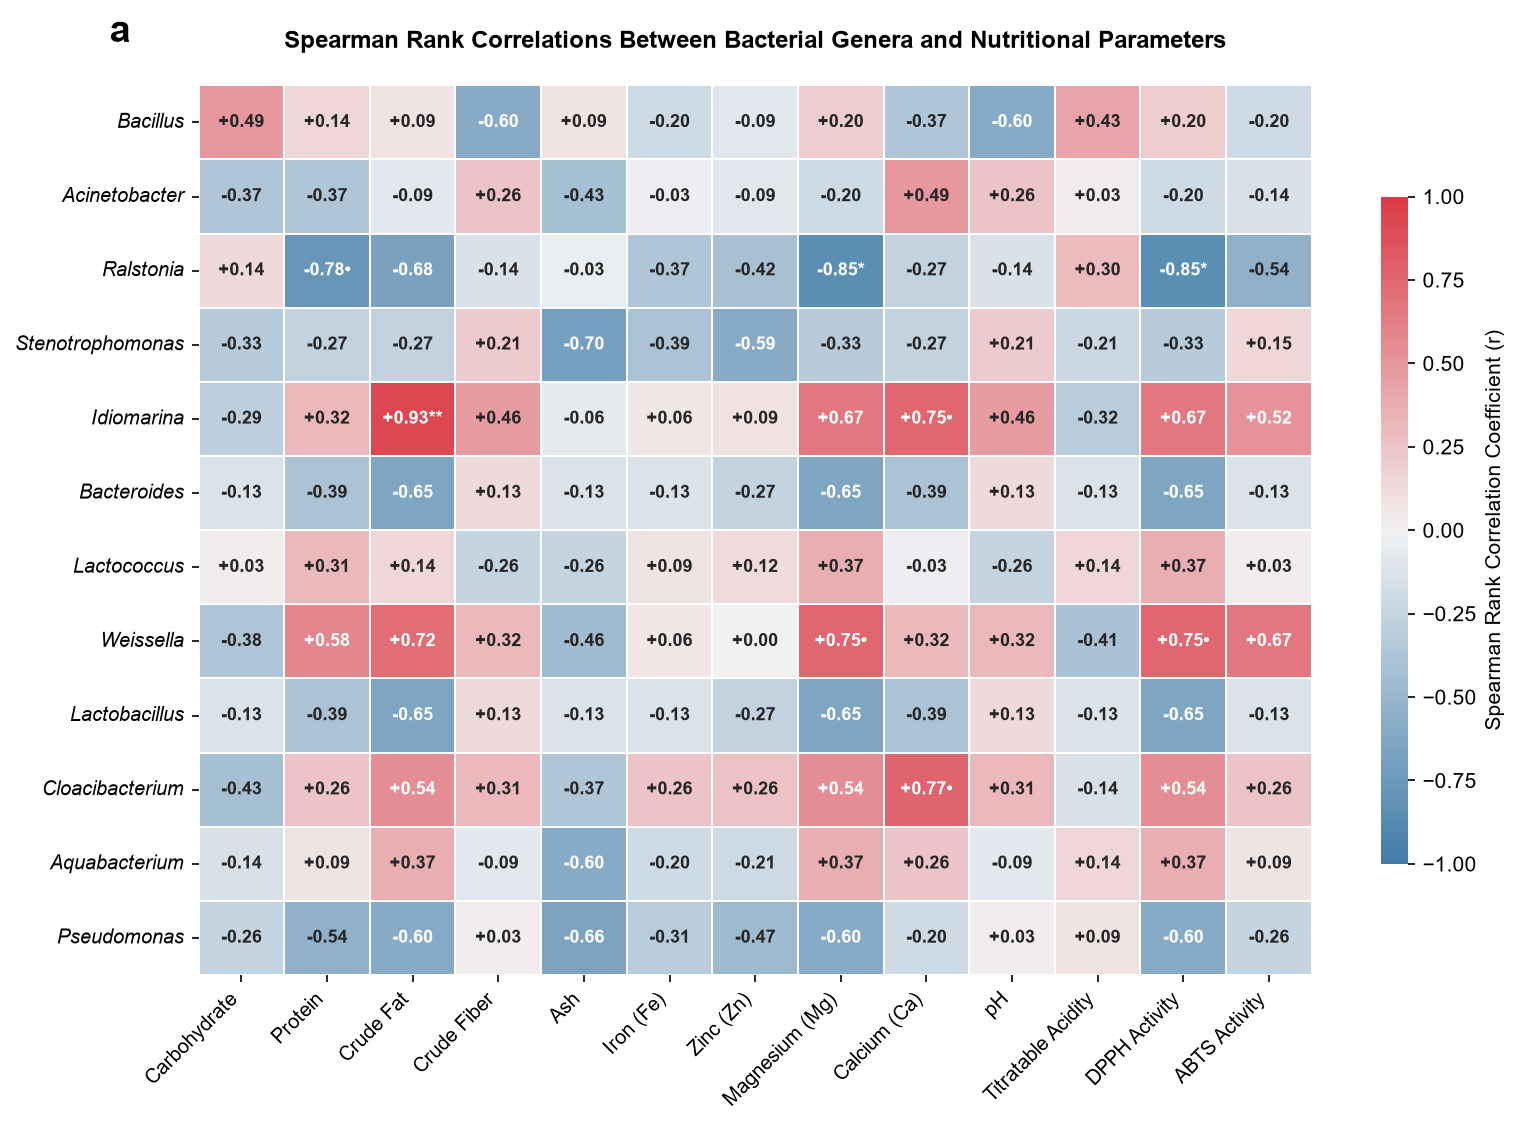

In [4]:
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
fig_h, ax_h = plt.subplots(figsize=(10.8, 7.6), dpi=150)
cmap = sns.diverging_palette(240, 10, as_cmap=True)

sns.heatmap(
    cor_r_num,
    annot=annot_matrix.values,
    fmt="",
    cmap=cmap,
    vmin=-1.0,
    vmax=1.0,
    center=0,
    linewidths=0.8,
    linecolor='white',
    cbar_kws={'label': "Spearman Rank Correlation Coefficient (r)", 'shrink': 0.75, 'aspect': 25},
    ax=ax_h,
    annot_kws={'size': 8.5, 'weight': 'bold'}
)

ax_h.text(-0.08, 1.04, 'a', transform=ax_h.transAxes, fontsize=18, fontweight='bold', fontname='Arial', va='bottom', ha='left')
ax_h.set_xticklabels([nut_label_map[c] for c in nut_vars], rotation=45, ha='right', fontsize=9.5, fontweight='medium')
ax_h.set_yticklabels(major_genera, rotation=0, fontsize=9.5, fontstyle='italic')
ax_h.set_title("Spearman Rank Correlations Between Bacterial Genera and Nutritional Parameters", fontsize=11.5, fontweight='bold', pad=18)
plt.tight_layout()
plt.show()


## 4. Figure 10: Constrained Redundancy Analysis (RDA) Biplot
Numerical ecology ordination capturing **75.58% total constrained variance** (RDA1 = 52.68%, RDA2 = 22.90%). 
Notice how traditional pigmented *Mapillai Samba* (MS) clusters along vectors for Protein, Fiber, Iron (Fe), Magnesium (Mg), and DPPH radical scavenging activity.

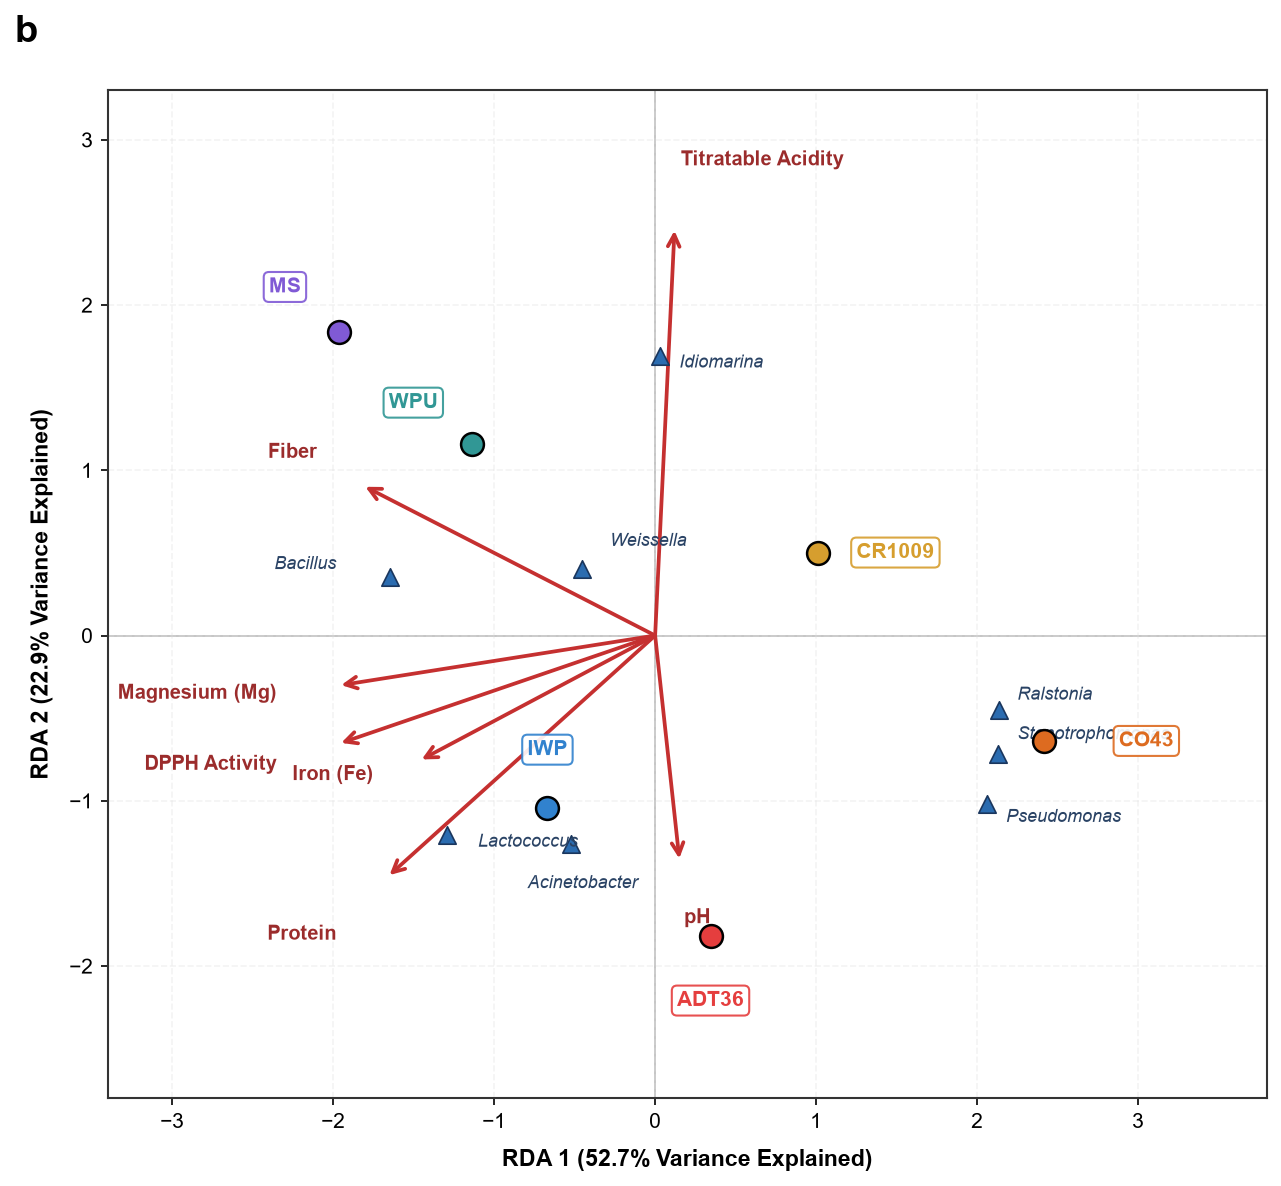

In [5]:
site_scores = {
    'ADT36': (0.344, -1.821), 'CO43': (2.416, -0.638), 'MS': (-1.966, 1.839),
    'IWP': (-0.669, -1.041), 'WPU': (-1.139, 1.159), 'CR1009': (1.014, 0.502)
}

env_vectors = {
    'Protein': (-1.65, -1.45), 'Iron (Fe)': (-1.45, -0.75), 'pH': (0.15, -1.35),
    'Titratable Acidity': (0.12, 2.45), 'DPPH Activity': (-1.95, -0.65),
    'Fiber': (-1.80, 0.90), 'Magnesium (Mg)': (-1.95, -0.30)
}

species_scores = {
    'Bacillus': (-1.644, 0.354), 'Lactococcus': (-1.292, -1.209), 'Weissella': (-0.455, 0.401),
    'Acinetobacter': (-0.522, -1.262), 'Ralstonia': (2.133, -0.450), 'Stenotrophomonas': (2.132, -0.720),
    'Idiomarina': (0.030, 1.694), 'Pseudomonas': (2.059, -1.020)
}

fig_b, ax_b = plt.subplots(figsize=(9.2, 8.0), dpi=150)
ax_b.set_facecolor('#ffffff')
for spine in ax_b.spines.values():
    spine.set_color('#333333')
    spine.set_linewidth(1.0)
ax_b.grid(True, linestyle='--', alpha=0.35, color='#dddddd', zorder=1)
ax_b.axhline(0, color='#bbbbbb', linestyle='-', linewidth=0.8, zorder=1)
ax_b.axvline(0, color='#bbbbbb', linestyle='-', linewidth=0.8, zorder=1)

env_label_pos = {
    'Protein': (-1.98, -1.75, 'right', 'top'), 'Iron (Fe)': (-1.75, -0.90, 'right', 'bottom'),
    'pH': (0.18, -1.65, 'left', 'top'), 'Titratable Acidity': (0.16, 2.82, 'left', 'bottom'),
    'DPPH Activity': (-2.35, -0.78, 'right', 'center'), 'Fiber': (-2.10, 1.05, 'right', 'bottom'),
    'Magnesium (Mg)': (-2.35, -0.35, 'right', 'center')
}

for nut_name, (vx, vy) in env_vectors.items():
    ax_b.annotate('', xy=(vx, vy), xytext=(0, 0),
                  arrowprops=dict(arrowstyle="->", color='#C53030', lw=1.8, mutation_scale=14, shrinkA=0, shrinkB=0), zorder=3)
    lx, ly, ha, va = env_label_pos[nut_name]
    ax_b.text(lx, ly, nut_name, color='#9B2C2C', fontsize=9.5, fontweight='bold', fontname='Arial', ha=ha, va=va, zorder=5)

taxa_label_pos = {
    'Bacillus': (-1.98, 0.38, 'right', 'bottom'), 'Lactococcus': (-1.10, -1.25, 'left', 'center'),
    'Weissella': (-0.28, 0.52, 'left', 'bottom'), 'Acinetobacter': (-0.45, -1.45, 'center', 'top'),
    'Ralstonia': (2.25, -0.36, 'left', 'center'), 'Stenotrophomonas': (2.25, -0.60, 'left', 'center'),
    'Idiomarina': (0.15, 1.65, 'left', 'center'), 'Pseudomonas': (2.18, -1.10, 'left', 'center')
}

for g_name, (gx, gy) in species_scores.items():
    ax_b.scatter(gx, gy, color='#2B6CB0', marker='^', s=70, edgecolor='#1A365D', linewidth=0.8, zorder=4)
    lx, ly, ha, va = taxa_label_pos[g_name]
    ax_b.text(lx, ly, g_name, color='#2A4365', fontsize=8.5, fontstyle='italic', fontname='Arial', ha=ha, va=va, zorder=5)

site_colors = {'ADT36': '#E53E3E', 'CO43': '#DD6B20', 'MS': '#805AD5', 'IWP': '#3182CE', 'WPU': '#319795', 'CR1009': '#D69E2E'}
site_label_pos = {
    'ADT36': (0.344, -2.15, 'center', 'top'), 'CO43': (2.88, -0.638, 'left', 'center'),
    'MS': (-2.20, 2.05, 'right', 'bottom'), 'IWP': (-0.669, -0.75, 'center', 'bottom'),
    'WPU': (-1.35, 1.35, 'right', 'bottom'), 'CR1009': (1.25, 0.502, 'left', 'center')
}

for s_name, (sx, sy) in site_scores.items():
    ax_b.scatter(sx, sy, color=site_colors[s_name], s=120, edgecolor='#000000', linewidth=1.2, zorder=6)
    lx, ly, ha, va = site_label_pos[s_name]
    ax_b.text(lx, ly, s_name, color=site_colors[s_name], fontsize=10.0, fontweight='bold', fontname='Arial',
              ha=ha, va=va, zorder=7,
              bbox=dict(boxstyle='round,pad=0.25', facecolor='#ffffff', edgecolor=site_colors[s_name], alpha=0.9, lw=1.0))

ax_b.set_xlabel("RDA 1 (52.7% Variance Explained)", fontsize=11, fontweight='bold', labelpad=8)
ax_b.set_ylabel("RDA 2 (22.9% Variance Explained)", fontsize=11, fontweight='bold', labelpad=8)
ax_b.text(-0.08, 1.04, 'b', transform=ax_b.transAxes, fontsize=18, fontweight='bold', fontname='Arial', va='bottom', ha='left')
ax_b.set_xlim(-3.4, 3.8)
ax_b.set_ylim(-2.8, 3.3)
plt.subplots_adjust(left=0.12, right=0.96, top=0.94, bottom=0.10)
plt.show()


## 5. Conclusions & Biological Synthesis
1. **Traditional Pigmented Rice (*Mappillai Samba*):** Demonstrates distinct multidimensional ordination driven by protein, dietary fiber, iron, magnesium, and DPPH radical scavenging capacity. Extracellular microbial phytases dephosphorylate grain phytates, liberating chelated minerals.
2. **Polished Grains (IWP, ADT36, CR1009):** Segregate toward high carbohydrate retention and away from functional mineral vectors due to bran removal.
3. **CO43:** Characterized by high opportunistic Proteobacteria (*Ralstonia*, *Stenotrophomonas*), which correlate inversely with magnesium ($r = -0.85^*$) and DPPH antioxidant retention ($r = -0.85^*$).
